# **Feature Selection**

## Filter Methods

Pearson’s Correlation

In [1]:
import numpy as np 
import pandas as pd
from scipy.stats import pearsonr

In [4]:
# Step 1: Create a small dataset
np.random.seed(42)
data = {
    'feature1': np.random.rand(10),
    'feature2': np.random.rand(10),
    'target': np.random.rand(10)
}
df = pd.DataFrame(data)

# Step 2: Calculate Pearson correlation
corr1, _ = pearsonr(df['feature1'], df['target'])
corr2, _ = pearsonr(df['feature2'], df['target'])

print(f"Pearson correlation between feature1 and target: {corr1:.2f}")
print(f"Pearson correlation between feature2 and target: {corr2:.2f}")

Pearson correlation between feature1 and target: -0.37
Pearson correlation between feature2 and target: -0.45


Chi-Square Test

In [6]:
from sklearn.feature_selection import chi2
from sklearn.preprocessing import LabelEncoder
import numpy as np

In [7]:
from sklearn.feature_selection import chi2
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Step 1: Create a small categorical dataset
data = np.array([
    ['low', 'yes'],
    ['medium', 'no'],
    ['medium', 'yes'],
    ['high', 'no'],
    ['low', 'yes'],
    ['high', 'no'],
])

# Step 2: Encode the categorical features and target
label_encoder = LabelEncoder()
X = label_encoder.fit_transform(data[:, 0])  # First column is feature (low, medium, high)
y = label_encoder.fit_transform(data[:, 1])  # Second column is target (yes, no)

# Step 3: Perform Chi-Square Test
chi_scores, p_values = chi2(X.reshape(-1, 1), y)
print(f"Chi-Square statistic: {chi_scores[0]:.2f}, p-value: {p_values[0]:.2f}")

Chi-Square statistic: 0.67, p-value: 0.41


ANOVA (Analysis of Variance)

In [10]:
from sklearn.datasets import load_iris
from sklearn.feature_selection import f_classif
import pandas as pd

# Step 1: Load Iris dataset
iris = load_iris()
X = iris.data  # Features
y = iris.target  # Target (3 different species)

# Step 2: Apply ANOVA (f_classif) to test significance of features
F_values, p_values = f_classif(X, y)

# Step 3: Display results
for i, feature in enumerate(iris.feature_names):
    print(f"{feature}: F-value = {F_values[i]:.2f}, p-value = {p_values[i]:.3f}")


sepal length (cm): F-value = 119.26, p-value = 0.000
sepal width (cm): F-value = 49.16, p-value = 0.000
petal length (cm): F-value = 1180.16, p-value = 0.000
petal width (cm): F-value = 960.01, p-value = 0.000


Kendall's and Spearman's Rank Correlation

In [11]:
from scipy.stats import spearmanr

# Step 1: Create a small dataset
data = {
    'feature1': [1, 2, 3, 4, 5],
    'feature2': [10, 9, 2, 6, 4],
    'target': [3, 2, 1, 5, 4]
}

df = pd.DataFrame(data)

# Step 2: Calculate Spearman's rank correlation
spearman_corr, _ = spearmanr(df['feature1'], df['target'])
print(f"Spearman's correlation between feature1 and target: {spearman_corr:.2f}")


Spearman's correlation between feature1 and target: 0.50


## Wrapper Methods

Recursive Feature Elimination (RFE) with SVM

In [12]:
# Step 1: Import necessary libraries
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.feature_selection import RFE
from sklearn.metrics import accuracy_score

In [13]:
# Step 2: Load the Breast Cancer dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

In [14]:
# Step 3: Split the data into training and testing sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [15]:
# Step 4: Initialize an SVM model with a linear kernel
svm_model = SVC(kernel='linear')

In [16]:
# Step 5: Perform Recursive Feature Elimination (RFE)
rfe = RFE(estimator=svm_model, n_features_to_select=10)  # Select top 10 features
rfe.fit(X_train, y_train)

,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).",SVC(kernel='linear')
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",10
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",1
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only available when `estimator` is a classifier.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: ``Estimator`` instanceThe fitted estimator used to select features.,SVC,SVC(kernel='linear')
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_ n_features_: intThe number of selected features.,int64,np.int64(10)
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,30


In [17]:
# Step 6: Check which features were selected
selected_features = X_train.columns[rfe.support_]
print("Selected Features by RFE:", selected_features)

Selected Features by RFE: Index(['mean radius', 'mean concavity', 'mean concave points', 'radius error',
       'texture error', 'worst smoothness', 'worst compactness',
       'worst concavity', 'worst concave points', 'worst symmetry'],
      dtype='str')


In [18]:
# Step 7: Train the model using only the selected features
X_train_rfe = rfe.transform(X_train)
X_test_rfe = rfe.transform(X_test)
svm_model.fit(X_train_rfe, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [19]:
# Step 8: Make predictions and evaluate the performance
y_pred = svm_model.predict(X_test_rfe)
accuracy = accuracy_score(y_test, y_pred)
print(f"Model accuracy with selected features: {accuracy:.2f}")

Model accuracy with selected features: 0.93


## Embedded Methods

Lasso (L1 Regularization) as an Embedded Method

In [20]:
# Step 1: Import necessary libraries
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error

In [21]:
# Step 2: Load the California Housing dataset
data = fetch_california_housing()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

In [22]:
# Step 3: Split the data into training and testing sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [23]:
# Step 4: Initialize the Lasso Regression model (L1 regularization)
lasso = Lasso(alpha=0.1)


In [24]:
# Step 5: Fit the model to the training data
lasso.fit(X_train, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [25]:
# Step 6: Check which features were selected (non-zero coefficients)
selected_features = X_train.columns[(lasso.coef_ != 0)]
print("Selected Features by Lasso:", selected_features)

Selected Features by Lasso: Index(['MedInc', 'HouseAge', 'Population', 'AveOccup', 'Latitude',
       'Longitude'],
      dtype='str')


In [26]:
# Step 7: Make predictions using the selected features
y_pred = lasso.predict(X_test)

In [27]:
# Step 8: Evaluate model performance using Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error with Lasso-selected features: {mse:.2f}")

Mean Squared Error with Lasso-selected features: 0.60


# **Dimension reduction**

PCA for Dimensionality Reduction

In [29]:
# Step 1: Import necessary libraries
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [30]:
# Step 2: Load the Iris dataset
data = load_iris()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

In [31]:
# Step 3: Standardize the data (PCA works best when data is normalized)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [32]:
# Step 4: Perform PCA
pca = PCA(n_components=2)  # Reduce to 2 dimensions for visualization
X_pca = pca.fit_transform(X_scaled)

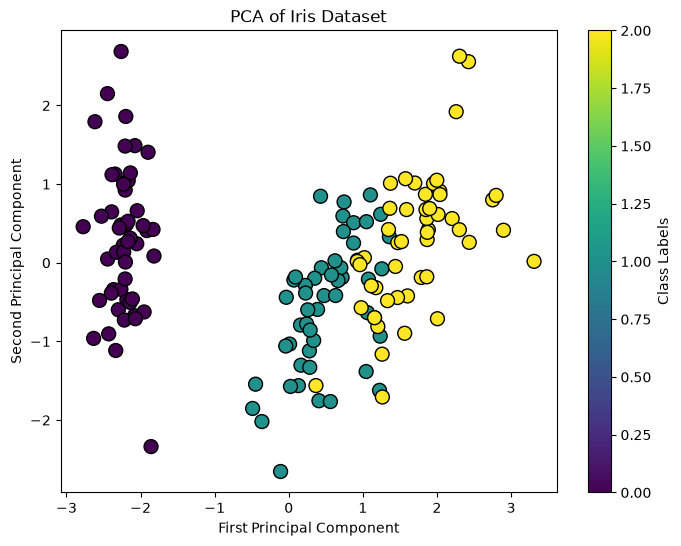

In [33]:
# Step 5: Visualize the transformed data in 2D
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', edgecolor='k', s=100)
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('PCA of Iris Dataset')
plt.colorbar(label='Class Labels')
plt.show()